# SAM3 Segmentation

SAM3 is a ViT-based segmentation model that can perform semantic segmentation on images using descriptive text prompts. Here we show how objects such as leaves but also parts of objects, such as the head of the bird, can be detected with such a model.

When running the code below, make sure you choose either the cluster or local paths for model and image.

In [ ]:
from ultralytics.models.sam import SAM3SemanticPredictor

# cluster
model_path = "/storage/research/dsl_vibe_rs/trainings/AICP/sam3.pt"
image_path = "/storage/research/dsl_vibe_rs/trainings/AICP/Blaumeise 028_0.jpeg"

# local
#model_path = "sam3.pt"
#image_path = "Blaumeise 028_0.jpeg"

# Initialize predictor with configuration
overrides = {
    "conf": 0.25,
    "task": "segment",
    "mode": "predict",
    #"model": "sam3.pt",
    "model": model_path,
    "quantize": 16,  # Use FP16 for faster inference
    "save": True,
}
predictor = SAM3SemanticPredictor(overrides=overrides)

# Set image once for multiple queries
#predictor.set_image("Blaumeise 028_0.jpeg")
predictor.set_image(image_path)

# Works with descriptive phrases
results = predictor(text=["head of bird", "leaves"])

Ultralytics 8.4.192 🚀 Python-3.14.0 torch-2.15.0 CPU (Apple M4 Pro)
WARNING ⚠️ imgsz=[640] must be multiple of max stride 14, updating to [644]

image 1/1 /Users/gw18g940/Desktop/CAS_AICP_M4-main2/Blaumeise 028_0.jpeg: 644x644 1 head of bird, 21 leavess, 394.6ms
Speed: 0.8ms preprocess, 394.6ms inference, 8.1ms postprocess per image at shape (1, 3, 644, 644)
Results saved to /Users/gw18g940/Desktop/CAS_AICP_M4-main2/runs/segment/predict


The output result is an object that contains the image, the masks and the coordinates of the boxes containing the detected objects. It can be plotted using Matplotlib:

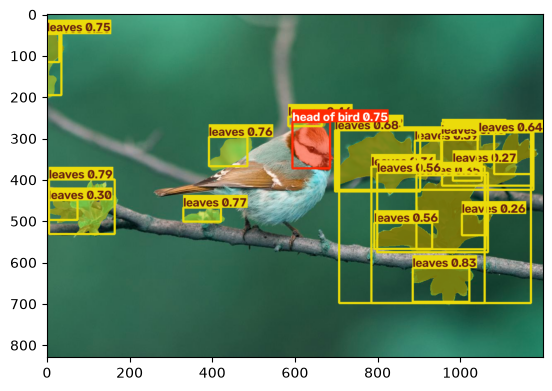

In [3]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot());

## Exercise

Use the SAM3 model to perform semantic segmentation on an image of your choice. Make sure to adapt the image to segment in the above code.